In [1]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import tensorflow as tf
from tensorflow import keras

/opt/conda/lib/python3.10/site-packages/scipy/__init__.py:146: UserWarning: A NumPy version >=1.16.5 and <1.23.0 is required for this version of SciPy (detected version 1.24.3
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"


In [2]:
dataset= "/kaggle/input/sugarcane-leaf-disease-dataset"

In [3]:
train = tf.keras.preprocessing.image_dataset_from_directory(
    dataset,
    labels="inferred",
    batch_size=40,
    image_size=(128,128),
    shuffle=True,
    seed=42,
    validation_split=0.2,
    subset="training"
)

test = tf.keras.preprocessing.image_dataset_from_directory(
    dataset,
    labels="inferred",
    batch_size=40,
    image_size=(128,128),
    seed=42,
    validation_split=0.2,
    subset="validation"
)

Found 2521 files belonging to 5 classes.
Using 2017 files for training.
Found 2521 files belonging to 5 classes.
Using 504 files for validation.


In [4]:
cat=train.class_names
cat

['Healthy', 'Mosaic', 'RedRot', 'Rust', 'Yellow']

In [5]:
for example_image, example_label in train.take(1):
  break

print(f"Image Shape: {example_image.shape}")

Image Shape: (40, 128, 128, 3)


In [6]:
validation_ds = test.shard(num_shards=2, index=0)
test_ds = test.shard(num_shards=2, index=1)

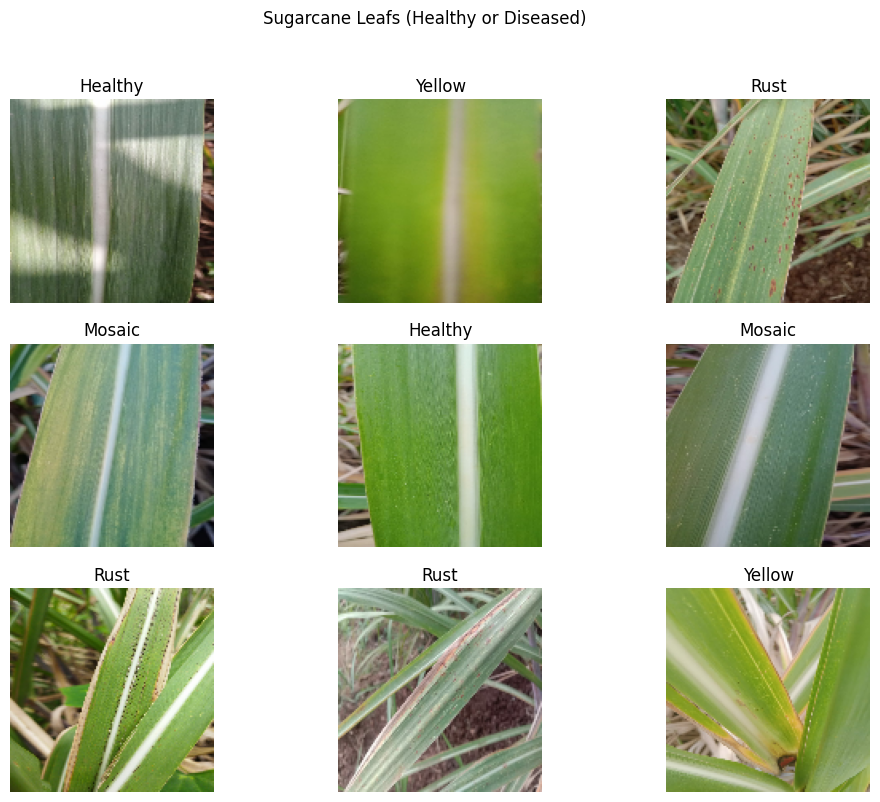

In [7]:
plt.figure(figsize=(12, 9))
for images, labels in train.take(1):
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(cat[labels[i]])
        plt.suptitle("Sugarcane Leafs (Healthy or Diseased)")
        plt.axis("off")

In [8]:
train_ds = train.cache().shuffle(250).prefetch(buffer_size=tf.data.AUTOTUNE)
validation_ds = validation_ds.cache().prefetch(buffer_size=tf.data.AUTOTUNE)
test_ds = test_ds.cache().prefetch(buffer_size=tf.data.AUTOTUNE)

In [9]:
base_model = tf.keras.applications.ResNet152V2(
    input_shape=(128, 128, 3),
    include_top=False,
    weights='imagenet'
)
base_model.trainable = True

print(len(base_model.layers))

234545216/234545216 [==============================] - 1s 0us/step
564


In [10]:
for layer in base_model.layers[:125]:
  layer.trainable = False

In [11]:
model = tf.keras.models.Sequential([
    tf.keras.layers.Rescaling(1./255),
    base_model,
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dropout(0.25),
    tf.keras.layers.Dense(len(cat))
])

In [12]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.01),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=['accuracy']
)

In [13]:
history = model.fit(
    train_ds,
    validation_data=validation_ds,
    epochs=100,
)

Epoch 1/100
51/51 [==============================] - 101s 386ms/step - loss: 2.0950 - accuracy: 0.2067 - val_loss: 212909917470720.0000 - val_accuracy: 0.2159
Epoch 2/100
51/51 [==============================] - 13s 255ms/step - loss: 1.6098 - accuracy: 0.2067 - val_loss: 1.6111 - val_accuracy: 0.1705
Epoch 3/100
51/51 [==============================] - 13s 260ms/step - loss: 1.6090 - accuracy: 0.2152 - val_loss: 1.6160 - val_accuracy: 0.1780
Epoch 4/100
51/51 [==============================] - 13s 263ms/step - loss: 1.6148 - accuracy: 0.2181 - val_loss: 1.6116 - val_accuracy: 0.1705
Epoch 5/100
51/51 [==============================] - 14s 269ms/step - loss: 1.6092 - accuracy: 0.2186 - val_loss: 1.6096 - val_accuracy: 0.1970
Epoch 6/100
51/51 [==============================] - 14s 270ms/step - loss: 1.6098 - accuracy: 0.2137 - val_loss: 1.6124 - val_accuracy: 0.1818
Epoch 7/100
51/51 [==============================] - 14s 267ms/step - loss: 1.6089 - accuracy: 0.2122 - val_loss: 1.6114 